In [7]:
import pandas as pd
import numpy as np

In [5]:
df=pd.read_csv("all_tickets_processed_improved_v3.csv")

In [6]:
df.head()

,Document,Topic_group
0,connection with icon icon dear please setup ic...,Hardware
1,work experience user work experience user hi w...,Access
2,requesting for meeting requesting meeting hi p...,Hardware
3,reset passwords for external accounts re expir...,Access
4,mail verification warning hi has got attached ...,Miscellaneous


In [4]:
df.shape

(47837, 2)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47837 entries, 0 to 47836
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Document     47837 non-null  object
 1   Topic_group  47837 non-null  object
dtypes: object(2)
memory usage: 747.6+ KB


In [6]:
#missing values
df.isnull().sum()

Document       0
Topic_group    0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.columns

Index(['Document', 'Topic_group'], dtype='object')

In [9]:
df["Topic_group"].value_counts()

Topic_group
Hardware                 13617
HR Support               10915
Access                    7125
Miscellaneous             7060
Storage                   2777
Purchase                  2464
Internal Project          2119
Administrative rights     1760
Name: count, dtype: int64

In [10]:
df["Document"].head()

0    connection with icon icon dear please setup ic...
1    work experience user work experience user hi w...
2    requesting for meeting requesting meeting hi p...
3    reset passwords for external accounts re expir...
4    mail verification warning hi has got attached ...
Name: Document, dtype: object

In [11]:
df["Topic_group"].unique()

array(['Hardware', 'Access', 'Miscellaneous', 'HR Support', 'Purchase',
       'Administrative rights', 'Storage', 'Internal Project'],
      dtype=object)

#### Text cleaning

In [12]:
#to clean unneccesary spaces,special characters(stopwords) in ticket discription before traing

In [8]:
import re #regular expression

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z0-9\s]', '', text)
    text = re.sub(r'\s+', ' ', text)
    return text

df["Cleaned document"] = df["Document"].apply(clean_text)

In [9]:
print(df[["Document", "Cleaned document"]].head())

                                            Document  \
0  connection with icon icon dear please setup ic...   
1  work experience user work experience user hi w...   
2  requesting for meeting requesting meeting hi p...   
3  reset passwords for external accounts re expir...   
4  mail verification warning hi has got attached ...   

                                    Cleaned document  
0  connection with icon icon dear please setup ic...  
1  work experience user work experience user hi w...  
2  requesting for meeting requesting meeting hi p...  
3  reset passwords for external accounts re expir...  
4  mail verification warning hi has got attached ...  


In [15]:
df["Cleaned document"].isnull().sum()

np.int64(0)

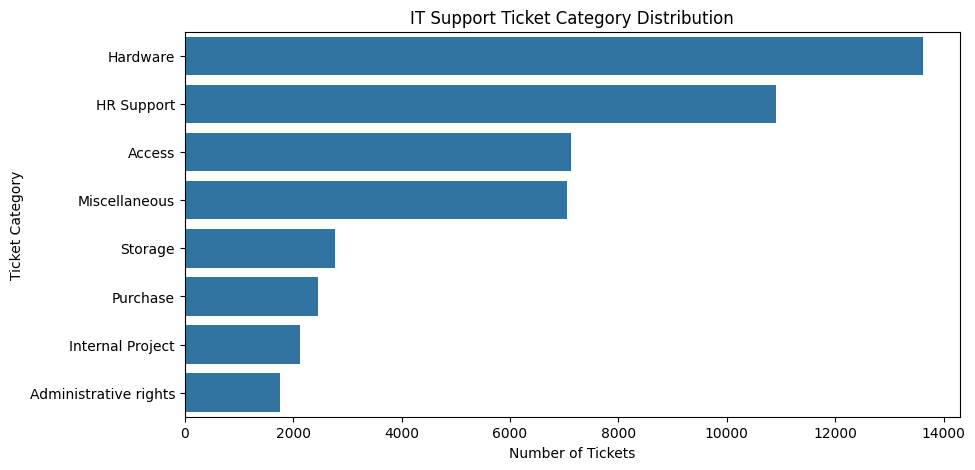

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.countplot(data=df, y="Topic_group",
              order=df["Topic_group"].value_counts().index)

plt.title("IT Support Ticket Category Distribution")
plt.xlabel("Number of Tickets")
plt.ylabel("Ticket Category")
plt.show()

#### Train-Test split

In [11]:
from sklearn.model_selection import train_test_split

X = df["Cleaned document"]#ticket text(input)
y = df["Topic_group"]#ticket category(target/output)

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data:", len(X_train))
print("Testing data:", len(X_test))

Training data: 38269
Testing data: 9568


#### TF-IDF vectorizer

In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000)

X_train_tfidf= tfidf.fit_transform(X_train)
X_test_tfidf= tfidf.transform(X_test)

print("TF-IDF completed successfully!")
print(X_train_tfidf.shape)
print(X_test_tfidf.shape)

TF-IDF completed successfully!
(38269, 5000)
(9568, 5000)


#### model build

In [16]:
from sklearn.linear_model import LogisticRegression

model=LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)
model.fit(X_train_tfidf,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


#### model prediction

In [17]:
y_pred=model.predict(X_test_tfidf)
y_pred

array(['Internal Project', 'HR Support', 'Miscellaneous', ...,
       'HR Support', 'Hardware', 'Storage'], shape=(9568,), dtype=object)

#### accuracy check

In [18]:
from sklearn.metrics import accuracy_score

In [19]:
accuracy=accuracy_score(y_test,y_pred)
accuracy

0.850752508361204

#### confusion metrix

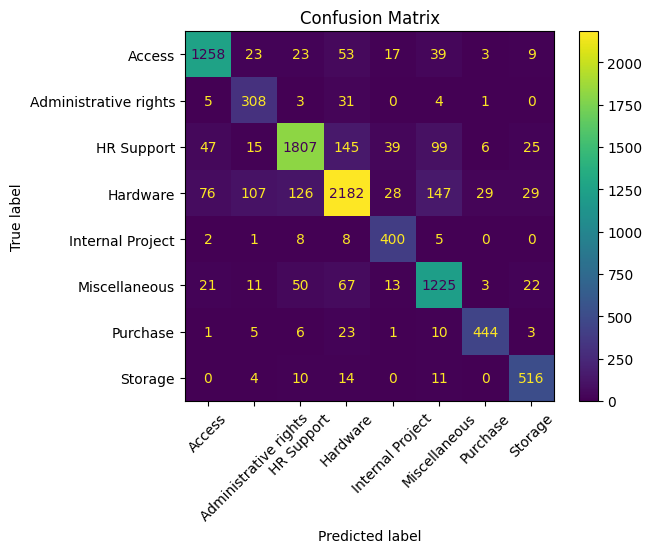

In [21]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

disp.plot(xticks_rotation=45)
plt.title("Confusion Matrix")
plt.show()

In [ ]:
#model testing

In [22]:
new_ticket = ["My laptop is not working properly"]

cleaned_ticket = clean_text(new_ticket[0])

ticket_tfidf =tfidf.transform([cleaned_ticket])

prediction =model.predict(ticket_tfidf)

print("Predicted Category:", prediction[0])

Predicted Category: Hardware


In [27]:
test_tickets = [
    "My laptop is not working",
    "I cannot access my account",
    "I need more storage space",
    "I need permission to access the company system",
    "I need to purchase a new office keyboard"
    
]

for ticket in test_tickets:
    cleaned = clean_text(ticket)
    ticket_tfidf = tfidf.transform([cleaned])
    prediction = model.predict(ticket_tfidf)
    print("Ticket:", ticket)
    print("Predicted Category:", prediction[0])
    print()

Ticket: My laptop is not working
Predicted Category: Hardware

Ticket: I cannot access my account
Predicted Category: Access

Ticket: I need more storage space
Predicted Category: Storage

Ticket: I need permission to access the company system
Predicted Category: HR Support

Ticket: I need to purchase a new office keyboard
Predicted Category: Purchase



#### neive bayes

In [28]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)


,alpha,1.0
,force_alpha,True
,fit_prior,True
,class_prior,None


In [29]:
nb_pred = nb_model.predict(X_test_tfidf)
nb_pred

array(['Internal Project', 'HR Support', 'Miscellaneous', ...,
       'HR Support', 'Hardware', 'Storage'], shape=(9568,), dtype='<U21')

In [30]:
nb_accuracy = accuracy_score(y_test, nb_pred)

print("Naive Bayes Accuracy:", nb_accuracy * 100)

Naive Bayes Accuracy: 76.92307692307693


#### Random Forest

In [31]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train_tfidf, y_train)

rf_pred = rf_model.predict(X_test_tfidf)

print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_pred) * 100)

Random Forest Accuracy: 84.27048494983278


#### model comparison table

In [32]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Naive Bayes", "Random Forest"],
    "Accuracy": [85.08, 76.92, 84.27]
})

comparison

,Model,Accuracy
0,Logistic Regression,85.08
1,Naive Bayes,76.92
2,Random Forest,84.27
